In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
import re
from rich.progress import track
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
# Now you can import your file
from regression_functions import *

## Look at results from metab x antibiotic use regressions on clinical chemistries

### Read in raw data for plotting

In [2]:
# ---- Read + merge ------------
labs_clean = pd.read_csv("../data/clincal_chems_abx_users_clean.csv", dtype={'public_client_id': str})
metabolites_merged = pd.read_csv("../data/metabolites_merged_used_for_regressions.csv", dtype={'public_client_id': str})

# Grab vendor
quest = labs_clean[labs_clean['vendor'] == 'Quest']
labcorp = labs_clean[labs_clean['vendor'] == 'LCA']

# Prepare labs for merge
lab_features = labs_clean.columns[31:].tolist()
cols = lab_features + ['vendor']
labs_clean.set_index('public_client_id', inplace=True)
labs_for_merge = labs_clean[cols].reset_index()

# Merge and set year var
labs_mets = metabolites_merged.merge(labs_for_merge, on='public_client_id', how='left')
labs_mets['abx_year'] = labs_mets['abx_recency'].apply(lambda x: "none" if x == "none" else "past_year")

metabolite_features = metabolites_merged.columns[27:].tolist()
not_offered_quest = quest[lab_features].isna().all().index[quest[lab_features].isna().all()].tolist()
not_offered_labcorp = labcorp[lab_features].isna().all().index[labcorp[lab_features].isna().all()].tolist()
individual_vendors = not_offered_labcorp + not_offered_quest
shared_labs = list(set(lab_features) - set(individual_vendors))

In [3]:
interaction_results = pd.read_csv("../data/metabolite_abx_interactions_on_labs.csv")

In [4]:
sig_interactions = interaction_results[interaction_results['q_value_global'] < 0.1].sort_values(by=['q_value_global','q_value'])

In [5]:
anns_snapshot = pd.read_csv("../data/metabolites_snapshot_updated.csv")
anns_snapshot = anns_snapshot.rename(columns={'feature':'metabolite'})

In [6]:
sig_ints_anns = sig_interactions.merge(anns_snapshot, on='metabolite', how='left')

In [7]:
lmplot_chems = sig_ints_anns.chemistry.value_counts()[sig_ints_anns.chemistry.value_counts() <= 3].index.tolist()

In [8]:
# sig_ints_anns.chemistry.value_counts()

In [9]:
lmplot_chems_df = sig_ints_anns[sig_ints_anns.chemistry.isin(lmplot_chems)]

In [10]:
lmplot_tuples = list(zip(lmplot_chems_df.chemistry, lmplot_chems_df.metabolite))
len(lmplot_tuples)

35

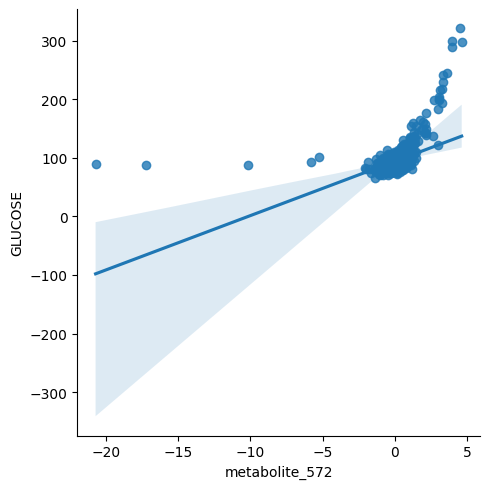

In [11]:
sns.lmplot(data=labs_mets, x='metabolite_572', y='GLUCOSE')

In [12]:
lmplot_tuples

[('GLUCOSE', 'metabolite_572'),
 ('ARSENIC_BLOOD', 'metabolite_565'),
 ('EPA_AA', 'metabolite_100003594'),
 ('GLYCOHEMOGLOBINA1C', 'metabolite_572'),
 ('HOMA_IR', 'metabolite_572'),
 ('BILIRUBIN_TOTAL', 'metabolite_1090'),
 ('HDLLARGE', 'metabolite_100006620'),
 ('ARSENIC_BLOOD', 'metabolite_100022120'),
 ('QUICKI', 'metabolite_572'),
 ('CHOLESTEROL_TOTAL', 'metabolite_266'),
 ('CREATININEENZ_SER', 'metabolite_100001662'),
 ('ALAT_SGPT_', 'metabolite_1083'),
 ('BILIRUBIN_TOTAL', 'metabolite_999946972'),
 ('HDLPARTICLENUMBER', 'metabolite_999946294'),
 ('LDL_SIZE', 'metabolite_100010919'),
 ('HOMOCYSTEINE_SERUM', 'metabolite_100009232'),
 ('COPPER_RBC', 'metabolite_100001948'),
 ('CRPHIGHSENSITIVITY', 'metabolite_100000961'),
 ('HOMOCYSTEINE_SERUM', 'metabolite_100001755'),
 ('CHOLESTEROL_TOTAL', 'metabolite_100005350'),
 ('CREATININEENZ_SER', 'metabolite_112'),
 ('BUN_CREATRATIO', 'metabolite_192'),
 ('ARSENIC_BLOOD', 'metabolite_100020219'),
 ('BILIRUBIN_TOTAL', 'metabolite_100022007'

In [13]:
covariates = ["C(sex)", "age", "BMI_CALC", "C(meds_cholesterol)",
              "C(meds_blood_sugar)", "PC1", "PC2", "PC3", "PC4", "PC5",
              "centered_eGFR", "C(vendor)"]
hits = pd.read_csv("../data/metabolite_abx_interactions_on_labs.csv")
hits = hits[hits["q_value_global"] < 0.1]          # your 117 hits
fig, bar = make_slope_barbell(labs_mets, hits, covariates)

NameError: name '_adjusted_std_slope' is not defined

GLUCOSE
ARSENIC_BLOOD
EPA_AA
GLYCOHEMOGLOBINA1C
HOMA_IR
BILIRUBIN_TOTAL
HDLLARGE
ARSENIC_BLOOD
QUICKI
CHOLESTEROL_TOTAL
CREATININEENZ_SER
ALAT_SGPT_
BILIRUBIN_TOTAL
HDLPARTICLENUMBER
LDL_SIZE
HOMOCYSTEINE_SERUM
COPPER_RBC


KeyboardInterrupt: 

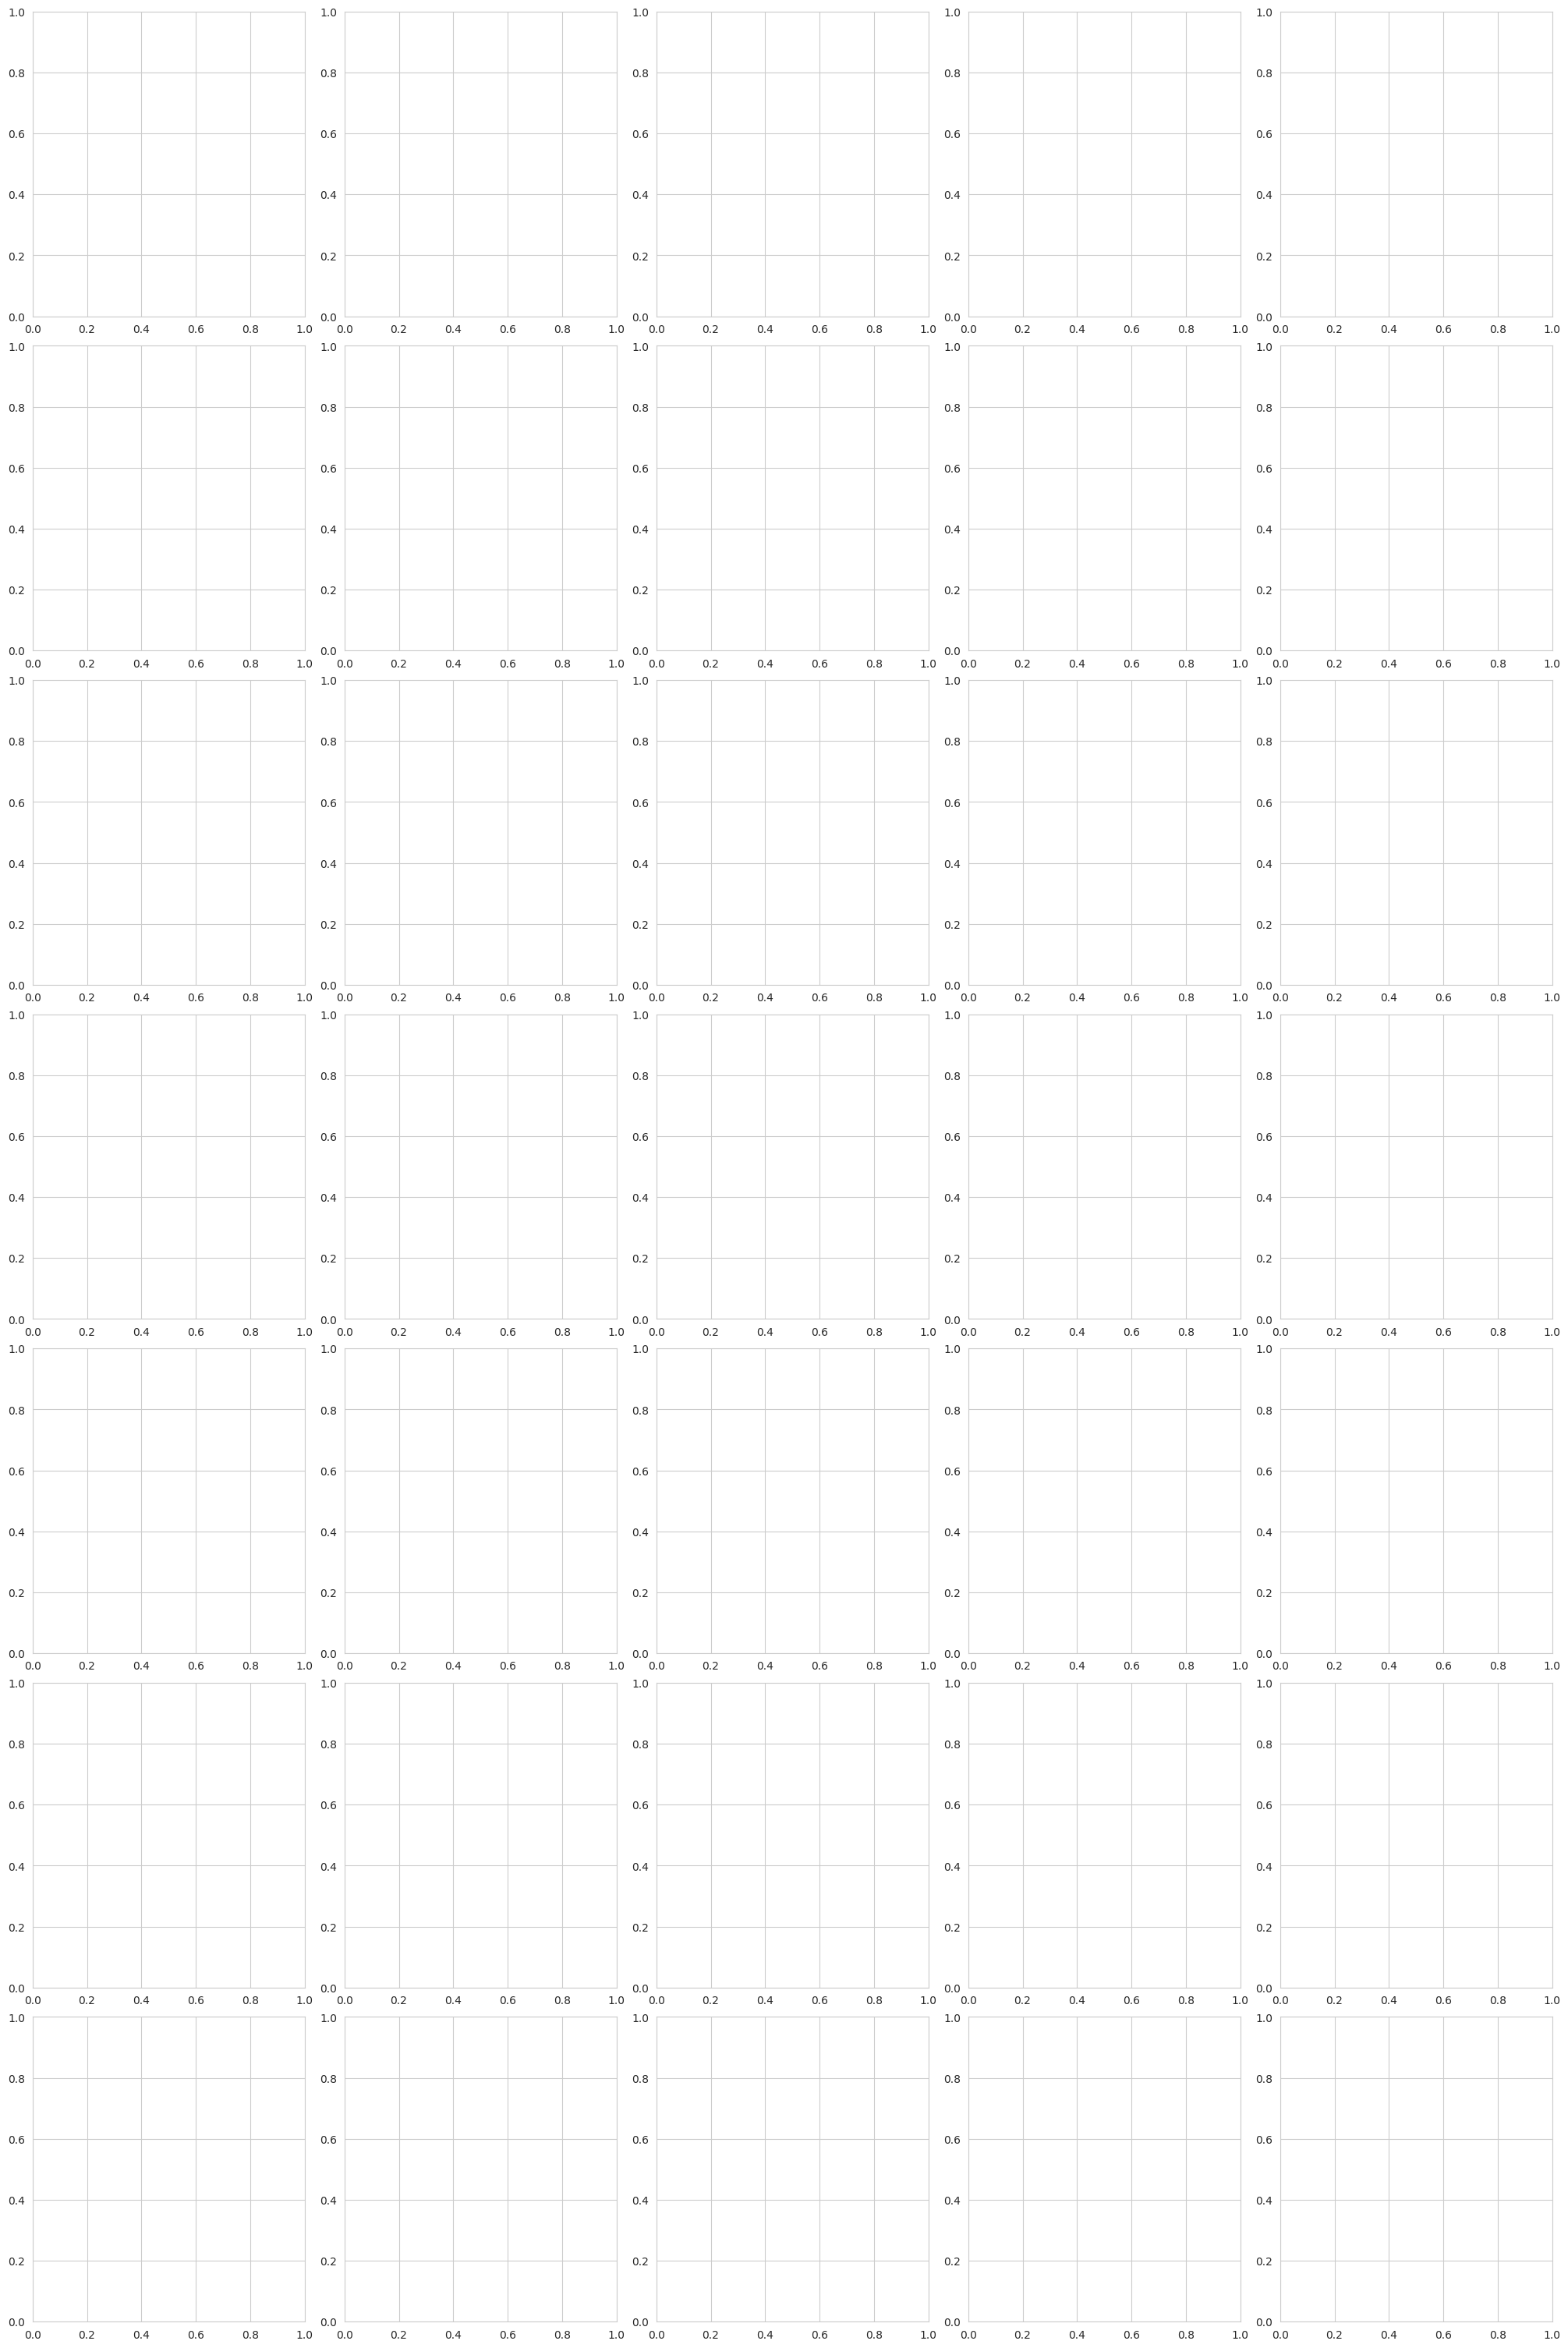

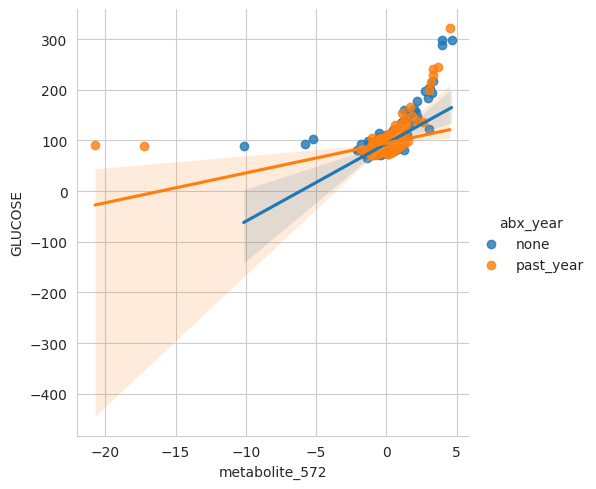

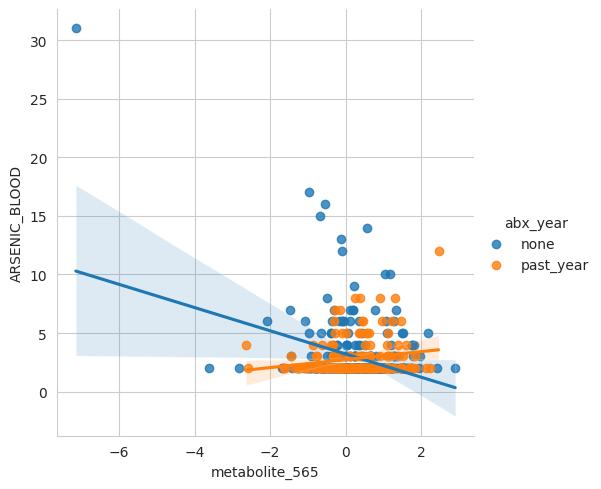

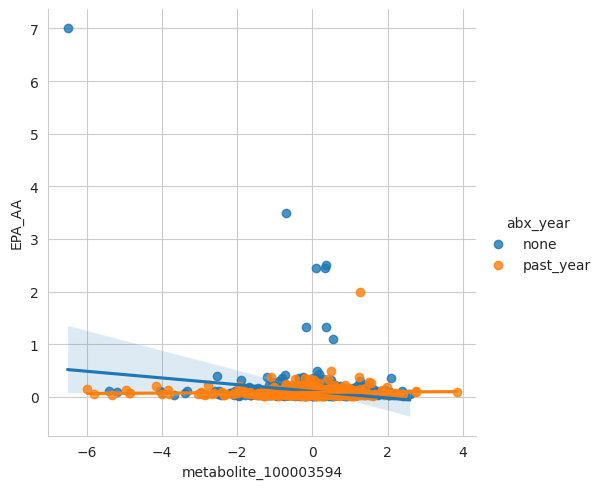

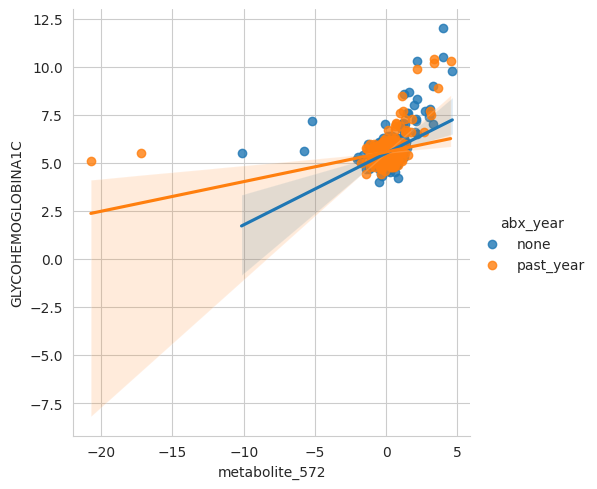

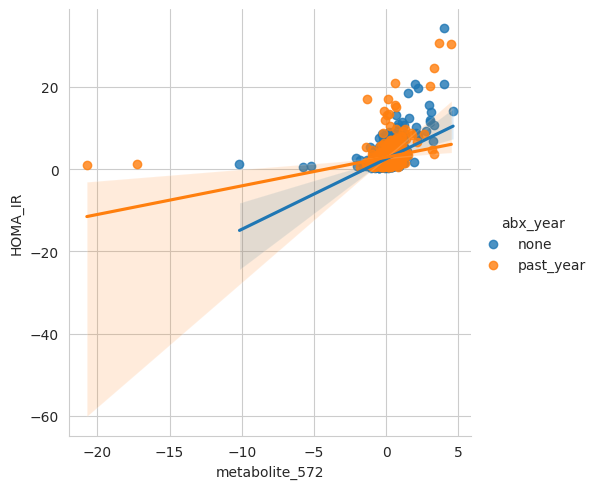

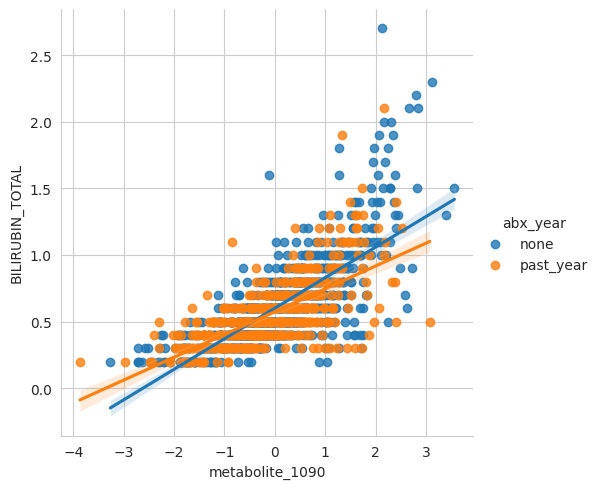

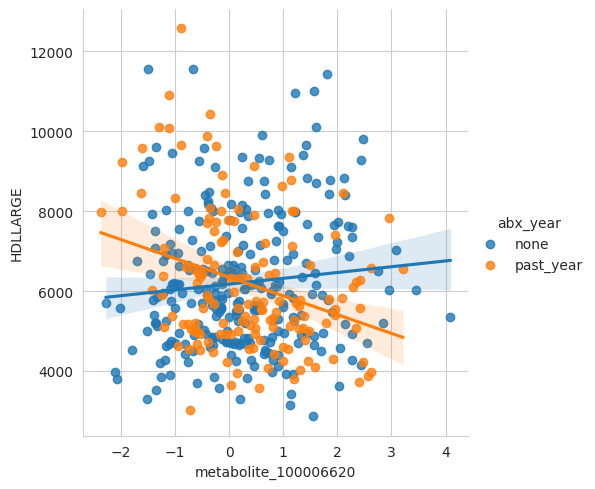

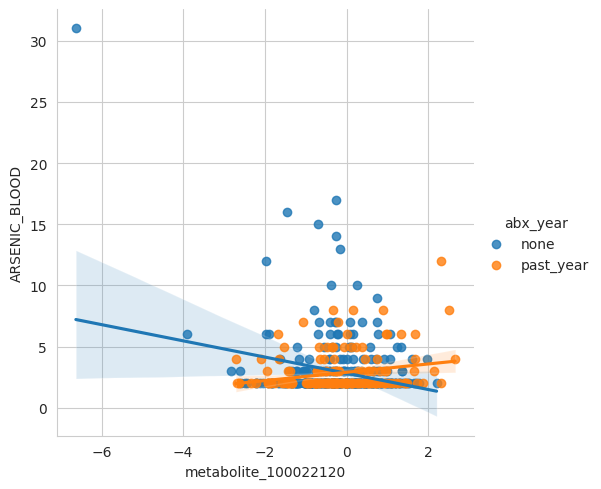

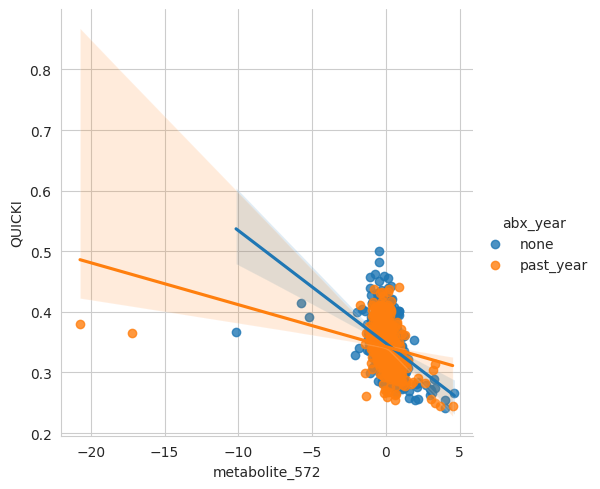

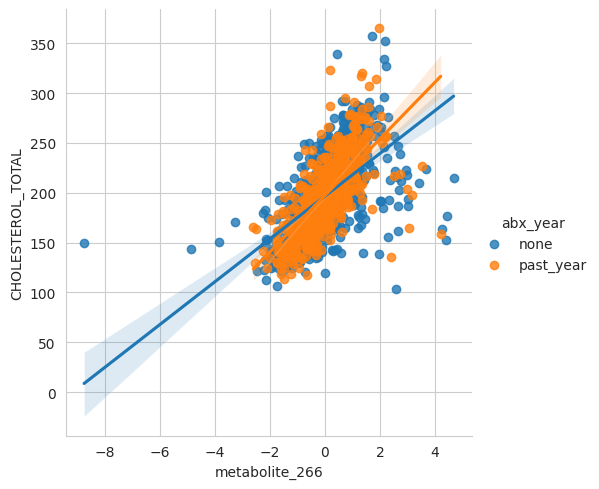

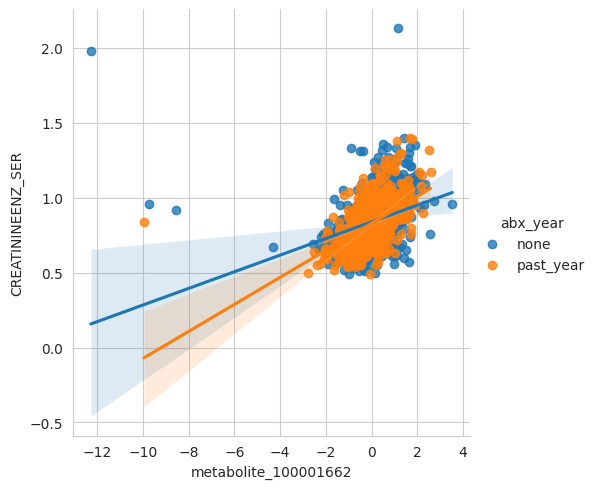

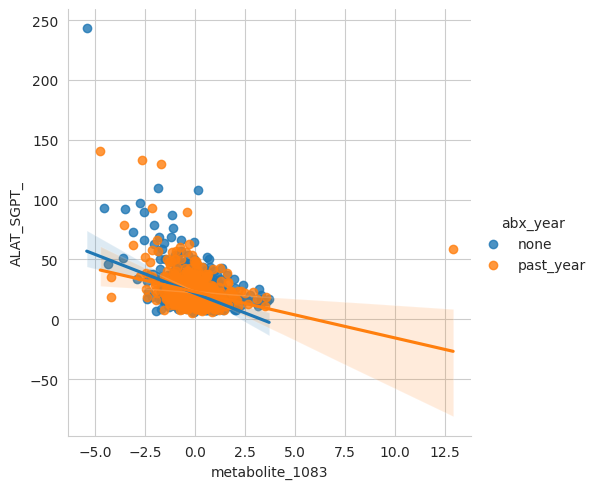

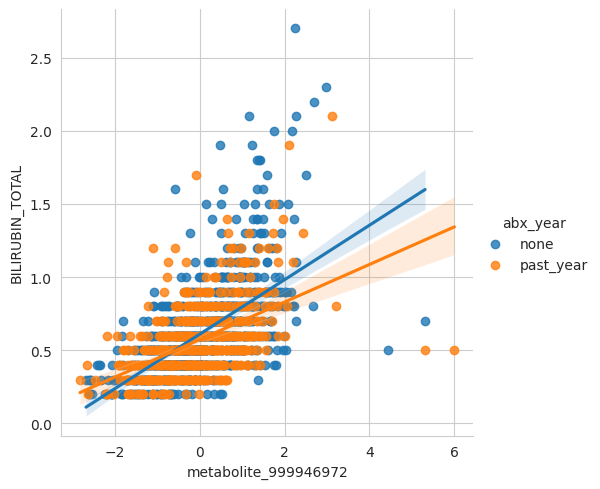

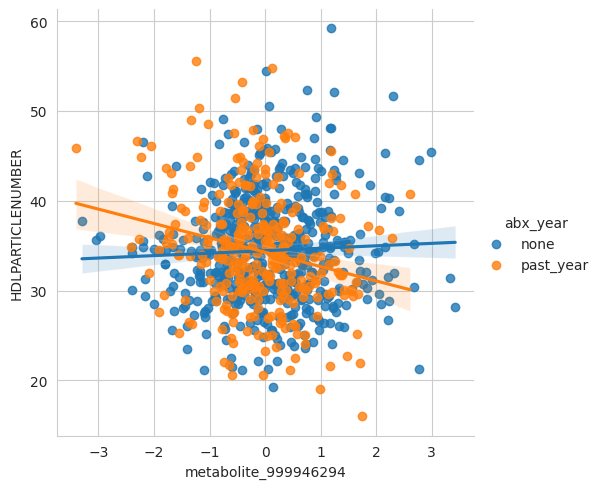

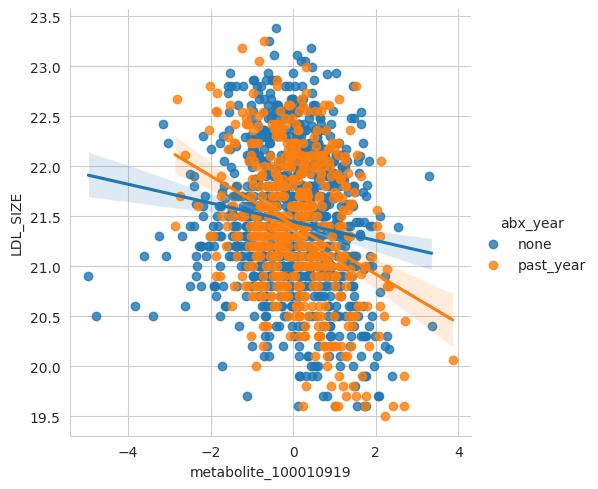

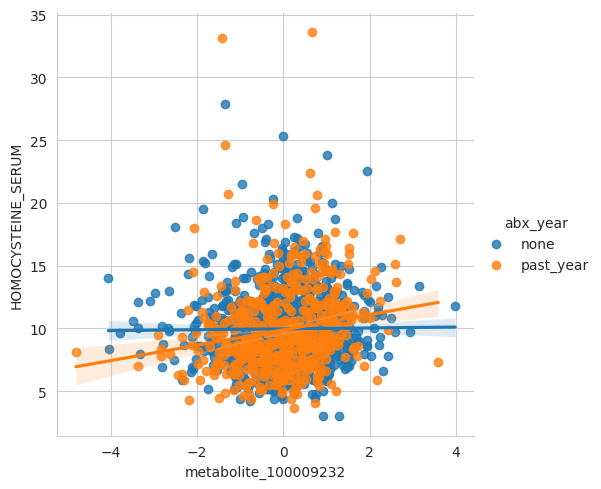

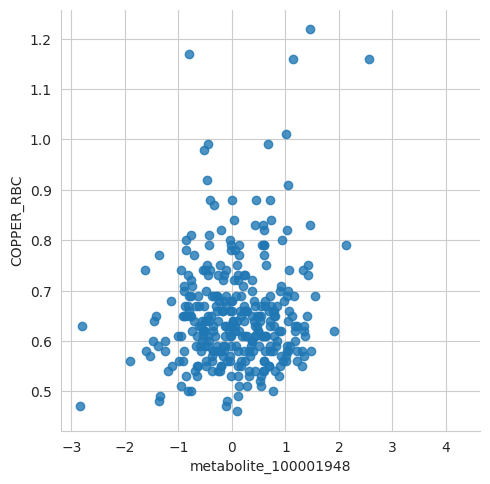

In [68]:
fig, axes = plt.subplots(nrows=7, ncols=5, figsize=(20, 30), constrained_layout=True)  
axes = axes.flatten()

for i, tuple_pair in enumerate(lmplot_tuples):
    sns.set_style("whitegrid")
    ax = axes[i]
    chem = lmplot_tuples[i][0]
    metab = lmplot_tuples[i][1]
    get_chem_name = sig_ints_anns[sig_ints_anns['chemistry'] == chem]['chemistry'].tolist()[0]
    get_plot_name = sig_ints_anns[sig_ints_anns['metabolite'] == metab]['CHEMICAL_NAME'].tolist()[0]
    #print(get_chem_name)
    if i == 0:
        sns.lmplot(data=labs_mets, x=metab, y=chem, hue='abx_year')
        # handles, labels = ax.get_legend_handles_labels()
        # new_labels = [legend_labels.get(label, label) for label in labels] # Replace labels 
        # ax.legend(handles, new_labels, title="Antibiotics in the last year")
        # sns.move_legend(ax, "upper right") 
    else:
        sns.lmplot(data=labs_mets, x=metab, y=chem, hue='abx_year')
    # current_positions = ax.get_xticks()
    # ax.set_xticks(current_positions, labels=x_labels)
    # ax.set_xlabel(f'{get_plot_name}')
    # ax.set_ylabel(f'log({get_chem_name}) Z-score')

# plt.savefig("figures/microbe_metab_interactions_pointplots.pdf") 
plt.show()

In [21]:
sig_ints_anns

,metabolite,beta,t_stat,p_value,n,q_value,chemistry,q_value_global,SUB_PATHWAY,SUPER_PATHWAY,CHEMICAL_NAME,CAS,KEGG,HMDB,PUBCHEM
0,metabolite_572,-6.820636,-9.377034,2.436871e-20,1504,2.361328e-17,GLUCOSE,2.219649e-15,"Glycolysis, Gluconeogenesis, and Pyruvate Meta...",Carbohydrate,glucose,50-99-7,C00031,HMDB0000122,5793
1,metabolite_100002989,0.587259,8.214959,4.557866e-16,1505,4.416572e-13,TriglycerideHDLRatio,2.075789e-11,Diacylglycerol,Lipid,oleoyl-linoleoyl-glycerol (18:1/18:2) [1],106292-55-1,NaN,HMDB0007219,14275396
2,metabolite_100002990,0.563914,7.812598,1.051519e-14,1503,5.094609e-12,TriglycerideHDLRatio,3.192621e-10,Diacylglycerol,Lipid,oleoyl-linoleoyl-glycerol (18:1/18:2) [2],104346-53-4,NaN,HMDB0007190,71433693
3,metabolite_100010919,0.582130,7.734664,1.894527e-14,1510,6.119323e-12,TriglycerideHDLRatio,4.314123e-10,Diacylglycerol,Lipid,oleoyl-oleoyl-glycerol (18:1/18:1) [2]*,NaN,NaN,HMDB0007188,9543716
4,metabolite_100010937,0.610525,7.611245,4.809652e-14,1495,1.165138e-11,TriglycerideHDLRatio,8.761839e-10,Diacylglycerol,Lipid,oleoyl-arachidonoyl-glycerol (18:1/20:4) [2]*,NaN,NaN,HMDB0007508,9543786
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,metabolite_100000936,-1.584681,-3.880102,1.089606e-04,1508,2.639572e-02,LYMPHOCYTES,8.710073e-02,"Leucine, Isoleucine and Valine Metabolism",Amino Acid,3-methyl-2-oxobutyrate,3715-29-5,C00141,HMDB0000019,49
113,metabolite_100000840,-0.573072,-3.880185,1.090122e-04,1480,3.521093e-02,HOMOCYSTEINE_SERUM,8.710073e-02,Food Component/Plant,Xenobiotics,tartronate (hydroxymalonate),80-69-3,C02287,HMDB0035227,45
114,metabolite_100000802,-0.394178,-3.868406,1.143015e-04,1497,1.107581e-01,EOSINOPHILS,9.053271e-02,"Fatty Acid Metabolism (Acyl Carnitine, Short C...",Lipid,acetylcarnitine (C2),5080-50-2,C02571,HMDB0000201,7045767
115,metabolite_100006641,24.549754,3.855256,1.208536e-04,1415,3.513857e-02,FERRITIN,9.489714e-02,Primary Bile Acid Metabolism,Lipid,glycochenodeoxycholate 3-sulfate,NaN,NaN,HMDB0002497,"21116917,21125002,11954205"
